## Imports

In [2]:
!python install_requirements.py;

In [330]:
import os
import random
from collections import Counter
import json

import pandas as pd
import numpy as np
from haversine import haversine, Unit

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, make_scorer, root_mean_squared_error
from sklearn.decomposition import PCA

import xgboost as xg
from xgboost import XGBRegressor, plot_importance

import torch

In [234]:
random.seed(1)
np.random.seed(1)
os.environ['PYTHONHASHSEED'] = str(1)

## Dataset

In [365]:
df = pd.read_csv("data/listings.csv")

In [366]:
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)

In [367]:
price_median = df['price'].median()
df['price'] = df['price'].fillna(price_median)

In [368]:
df['host_is_superhost'] = df['host_is_superhost'].map({'t': 1, 'f': 0})

In [369]:
# instant bookable as feature
# host_acceptance/response_rate string to numerical

In [370]:
#fill missing bathrooms (drop in the end if still missing)


In [371]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=1) # this needs to be implemented

#### Embeddings

In [372]:
desc_emb = pd.read_csv("data/description_embeddings.csv")
# Separate ID and embeddings
ids = desc_emb['id']
embeddings = desc_emb.drop(columns=['id'])

# Apply PCA
desc_pca = PCA(n_components=200).fit_transform(embeddings)

# Turn PCA result into a DataFrame and reattach IDs
desc_pca_df = pd.DataFrame(desc_pca, columns=[f'desc_pca_{i}' for i in range(desc_pca.shape[1])])
desc_pca_df['id'] = ids.values  # make sure ID aligns correctly

# Merge with your main DataFrame
df = pd.merge(df, desc_pca_df, on='id', how='left')

In [373]:
desc_columns = [col for col in df.columns if col.startswith('desc_')]

In [374]:
ti_emb = pd.read_csv("data/title_embeddings.csv")

# Separate ID and embeddings
ids = ti_emb['id']
embeddings = ti_emb.drop(columns=['id'])

# Apply PCA
ti_pca = PCA(n_components=200).fit_transform(embeddings)

# Turn PCA result into a DataFrame and reattach IDs
ti_pca_df = pd.DataFrame(ti_pca, columns=[f'title_pca_{i}' for i in range(ti_pca.shape[1])])
ti_pca_df['id'] = ids.values  # make sure ID aligns correctly

# Merge with your main DataFrame
df = pd.merge(df, ti_pca_df, on='id', how='left')

In [375]:
ti_columns = [col for col in df.columns if col.startswith('title_')]

#### Derived Features

In [376]:
# shared bathroom

In [377]:
sentiments = pd.read_csv("data/sentiment_features.csv")

In [378]:
df = pd.merge(df, sentiments, left_on='id', right_on='listing_id', how='left')
df.drop(columns='listing_id', inplace=True)
df.drop(columns='sentiment_scores', inplace=True)

#### Spatial Features

In [379]:
city_center = (25.049589097552495, 121.5136645234154) # Taipei City Mall

In [380]:
def compute_distance(row): # add parameter for different 'centers'
    coords = (row['latitude'], row['longitude'])
    return haversine(city_center, coords, unit=Unit.KILOMETERS)

In [381]:
df['dist_to_cent'] = df.apply(compute_distance, axis=1)

#### Categorical Features

##### Neighbourhoods

In [382]:
nh_matrix = pd.get_dummies(df['neighbourhood_cleansed'])
nh_matrix = nh_matrix.add_prefix('nh_')
df = pd.concat([df, nh_matrix], axis=1)

In [383]:
nh_columns = [col for col in df.columns if col.startswith('nh_')]

##### Amenities

In [384]:
df['amenities'] = df['amenities'].apply(json.loads)

In [385]:
all_amenities = [amenity for sublist in df['amenities'] for amenity in sublist]
unique_amenities = sorted(set(all_amenities))

In [386]:
#count lock on bedroom door  

In [387]:
lower_threshold = 500 #600
upper_threshold = 5500 #5000
amenity_counts = Counter(all_amenities)

filtered_amenities = {
    amenity
    for amenity, count in amenity_counts.items()
    if lower_threshold <= count <= upper_threshold
}

In [388]:
def encode_amenities(row_amenities):
    return {
        amenity: int(amenity in row_amenities)
        for amenity in filtered_amenities # can be changed
    }

In [389]:
am_matrix = df['amenities'].apply(encode_amenities).apply(pd.Series)
am_matrix = am_matrix.add_prefix('am_')
df = pd.concat([df, am_matrix], axis=1)

In [390]:
am_columns = [col for col in df.columns if col.startswith('am_')]

##### Room types

In [391]:
rt_matrix = pd.get_dummies(df['room_type'])
rt_matrix = rt_matrix.add_prefix('rt_')
df = pd.concat([df, rt_matrix], axis=1)

In [392]:
rt_columns = [col for col in df.columns if col.startswith('rt_')]

#### Image Features

In [393]:
img = pd.read_csv("data/image_features_pca.csv")

In [394]:
# Apply PCA
img_pca = PCA(n_components=200).fit_transform(img)

# Convert back to DataFrame
img_pca_df = pd.DataFrame(img_pca, columns=[f'img_pca_{i}' for i in range(img_pca.shape[1])])

# Concatenate to your main DataFrame
df = pd.concat([df.reset_index(drop=True), img_pca_df], axis=1)

In [395]:
img_columns = [col for col in df.columns if col.startswith('img_')]

#### Capping

##### Analysis

In [52]:
# Exploring the data set - listing every hostel with bathrooms/bedrooms
filtered_df = df.loc[df['property_type'].str.contains("hostel", case=False, na=False), ['property_type', 'price', 'accommodates', 'bathrooms', 'bedrooms', 'beds']]

In [43]:
pd.set_option('display.max_rows', None)
filtered_df

,property_type,price,accommodates,bathrooms,bedrooms,beds
17,Room in hostel,2723.0,2,1.0,1.0,1.0
96,Shared room in hostel,756.0,10,3.0,2.0,2.0
149,Private room in hostel,1355.0,2,1.0,1.0,1.0
183,Private room in hostel,1355.0,2,1.0,1.0,1.0
200,Room in hostel,3751.0,5,6.0,1.0,4.0
290,Room in hostel,2093.0,2,NaN,1.0,NaN
291,Room in hostel,2093.0,2,NaN,1.0,NaN
292,Room in hostel,1642.0,2,5.0,1.0,2.0
294,Room in hostel,1737.0,2,5.0,1.0,2.0
299,Room in hostel,1737.0,2,5.0,1.0,1.0


In [40]:
# Filter hostels and drop rows with NaNs in beds, bathrooms, bedrooms
hostels = df.loc[
    df['property_type'].str.contains("hostel", case=False, na=False), 
    ['property_type', 'price', 'accommodates', 'bathrooms', 'bedrooms', 'beds']
].dropna(subset=['accommodates', 'price', 'bathrooms', 'bedrooms', 'beds'])

# Calculate average beds, bathrooms, bedrooms grouped by property_type
averages = hostels.groupby('property_type').agg({
    'price': 'mean',
    'beds': 'mean',
    'bathrooms': 'mean',
    'bedrooms': 'mean',
    'accommodates': 'mean'
}).reset_index()

print(averages)

            property_type        price      beds  bathrooms  bedrooms  \
0  Private room in hostel  3101.833333  2.000000   2.583333  1.000000   
1          Room in hostel  2453.969697  4.090909   3.818182  1.000000   
2   Shared room in hostel  1399.266667  3.866667   3.033333  1.066667   

   accommodates  
0      2.083333  
1      2.030303  
2      3.600000  


In [41]:
overall_avg = hostels[['accommodates', 'price', 'bathrooms', 'bedrooms', 'beds']].mean()
print(overall_avg)


accommodates       2.433333
price           2319.866667
bathrooms          3.375000
bedrooms           1.016667
beds               3.616667
dtype: float64


## Model

==== CONFIG ====

In [410]:
USE_LOG = True
CAP_HIGH = 15000 #15000
CAP_LOW = 500 #300
APPLY_CAPS = True #implement
REMOVE_OUTLIERS = False #implement

FEATURE_GROUPS_FULL = {
    "base": ['accommodates', 'bathrooms', 'bedrooms', 'beds', 'review_scores_rating', 'dist_to_cent', 'minimum_nights', 'maximum_nights', 'host_is_superhost', 'host_total_listings_count', 'availability_eoy', 'host_listings_count', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'latitude', 'longitude', 'avg_sentiment', 'std_sentiment', 'min_sentiment', 'max_sentiment'],
    "neighborhood": nh_columns,
    "amenities": am_columns,
    "room_type": rt_columns,
    "images": img_columns,
    "titles": ti_columns,
    "descriptions": desc_columns,
}

FEATURE_GROUPS = {
    "base": ['accommodates', 'bathrooms', 'bedrooms', 'beds', 'review_scores_rating', 'dist_to_cent', 'minimum_nights', 'maximum_nights', 'host_is_superhost', 'host_total_listings_count', 'host_listings_count', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_nights_avg_ntm', 'availability_30', 'availability_60', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'latitude', 'longitude', 'avg_sentiment', 'std_sentiment', 'min_sentiment', 'max_sentiment'],
    "neighborhood": nh_columns,
    "amenities": am_columns, # needs further tweaking
    "room_type": rt_columns,
    #"images": img_columns,
    #"titles": ti_columns,
    #"descriptions": desc_columns,
}

MODEL_NAME = "xgb"  # 'rf' or 'xgb'
TEST_SIZE = 0.2
RANDOM_SEED = 8

In [398]:
def get_model(name):
    if name == "rf":
        return RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED)
    elif name == "xgb":
        return XGBRegressor(subsample=0.7, reg_lambda=5, reg_alpha=0.5, n_estimators=200, min_child_weight=3, max_depth=7, learning_rate=0.05, colsample_bytree=0.7, random_state=RANDOM_SEED)

In [268]:
def preprocess_data(df, cap_low, cap_high, feature_groups, use_log):
    df = df.copy()
    df['price_capped'] = df['price'].clip(lower=cap_low, upper=cap_high)

    if use_log:
        df['target'] = np.log1p(df['price_capped'])
    else:
        df['target'] = df['price_capped']

    selected_features = []
    for group in feature_groups.values():
        selected_features += group

    X = df[selected_features]
    y = df['target']

    return X, y

    #valid_idx = (df.loc[X.index, 'price'] < 8000) & (df.loc[X.index, 'price'] > 300)
    #X = X.loc[valid_idx]
    #y = y.loc[valid_idx]

In [269]:
def evaluate_model(model, X, y, use_log): #implement whole config file as parameter
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    if use_log:
        y_test_raw = np.expm1(y_test)
        y_pred_raw = np.expm1(y_pred)
    else:
        y_test_raw = y_test
        y_pred_raw = y_pred

    rmse = np.sqrt(mean_squared_error(y_test_raw, y_pred_raw))
    mape = np.mean(np.abs((y_test_raw - y_pred_raw) / y_test_raw)) * 100

    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2f}%")

    return y_test_raw, y_pred_raw

In [270]:
def plot_results(y_true, y_pred, label=''):
    residuals = y_true - y_pred

    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.5, edgecolor='k')
    plt.plot([0, y_true.max()], [0, y_true.max()], color='red', lw=2, label='Perfect prediction')
    plt.xlabel('True Price')
    plt.ylabel('Predicted Price')
    plt.title(f'Predicted vs True Prices {label}')
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.scatter(y_true, residuals, alpha=0.5, edgecolor='k')
    plt.axhline(0, color='red')
    plt.xlabel('True Price')
    plt.ylabel('Residuals')
    plt.title(f'Residuals vs True Price {label}')
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.scatter(y_pred, residuals, alpha=0.5, edgecolor='k')
    plt.axhline(0, color='red')
    plt.xlabel('Predicted Price')
    plt.ylabel('Residuals')
    plt.title(f'Residuals vs Predicted Price {label}')
    plt.grid(True)
    plt.show()

In [411]:
X, y = preprocess_data(df, CAP_LOW, CAP_HIGH, FEATURE_GROUPS, USE_LOG)

In [347]:
model = get_model(MODEL_NAME)
y_true, y_pred = evaluate_model(model, X, y, use_log=USE_LOG)

RMSE: 1192.07
MAPE: 22.02%


In [412]:
y_true, y_pred = evaluate_model_kfold(model, X, y, use_log=USE_LOG, n_splits=10)

Average RMSE: 1425.87 ± 186.62
Average MAPE: 22.70% ± 0.91
Average Bias: -214.21 ± 64.16


In [413]:
bucket_evalutation(y_true, y_pred)

            count         RMSE       MAPE         Bias
bucket                                                
<1000         706   505.317137  43.352264   280.720649
1000-2000    1817   471.293019  21.487121   171.340171
2000-4000    2476   627.794974  16.229788   -16.418269
4000-6000     635  1235.573522  20.012567  -641.911022
6000-10000    234  2735.888016  29.940284 -2072.572267
>10000        109  8609.241311  56.291719 -7858.384191


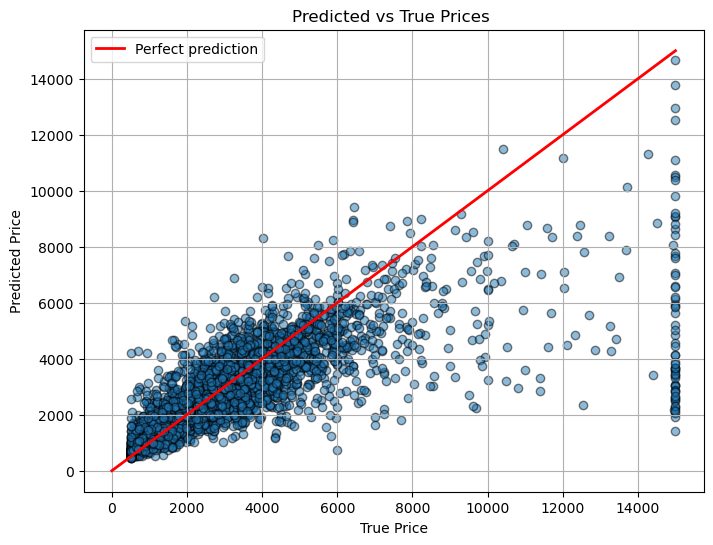

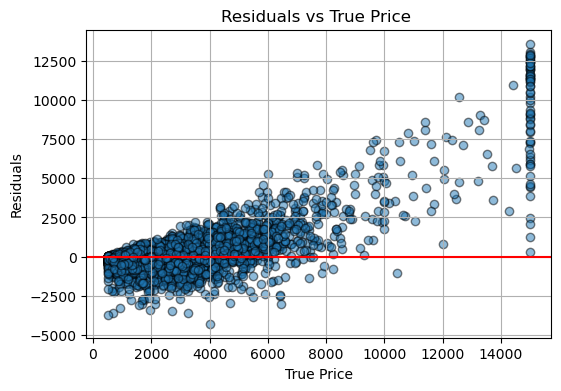

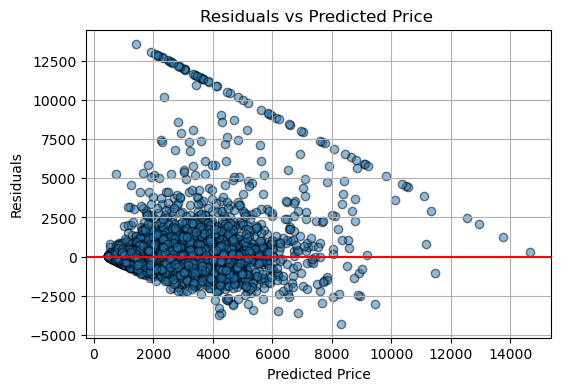

In [414]:
plot_results(y_true, y_pred)

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

/opt/conda/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from current font.
  func(*args, **kwargs)
/opt/conda/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Glyph 21516 (\N{CJK UNIFIED IDEOGRAPH-540C}) missing from current font.
  func(*args, **kwargs)
/opt/conda/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Glyph 21312 (\N{CJK UNIFIED IDEOGRAPH-5340}) missing from current font.
  func(*args, **kwargs)
/opt/conda/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Glyph 20449 (\N{CJK UNIFIED IDEOGRAPH-4FE1}) missing from current font.
  func(*args, **kwargs)
/opt/conda/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Glyph 32681 (\N{CJK UNIFIED IDEOGRAPH-7FA9}) missing from current font.
  func(*args, **kwargs)
/opt/conda/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E

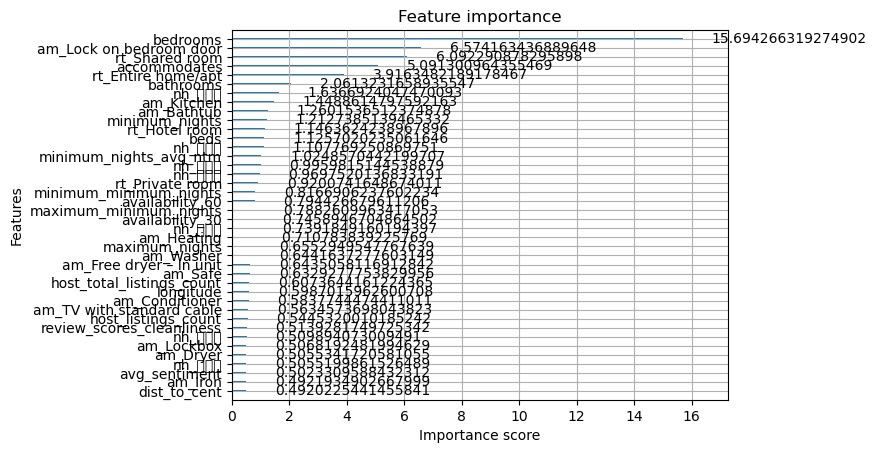

In [346]:
plot_importance(model, importance_type='gain', max_num_features=40)

#### Buckets

In [206]:
# 1. Define bins and labels
def bucket_evalutation(y_true, y_pred):
    bins = [0, 1000, 2000, 4000, 6000, 10000, np.inf]
    labels = ['<1000', '1000-2000', '2000-4000', '4000-6000', '6000-10000', '>10000']

    # 2. Bin the true values
    bucket = pd.cut(y_true, bins=bins, labels=labels)

    # 3. Build a tiny DataFrame
    df_metrics = pd.DataFrame({
        'y_true': y_true.values,
        'y_pred': y_pred,
        'bucket': bucket
    })

    # 4. Group and compute
    results = (df_metrics
        .groupby('bucket', observed=True)
        .agg(
            count=('y_true', 'size'),
            RMSE=('y_true', lambda x: root_mean_squared_error(x, df_metrics.loc[x.index, 'y_pred'])),
            MAPE=('y_true', lambda x: mean_absolute_percentage_error(x, df_metrics.loc[x.index, 'y_pred']) * 100),
            Bias=('y_pred', lambda x: (x - df_metrics.loc[x.index, 'y_true']).mean())
        )
    )

    print(results)

#### K-Fold

In [203]:
def evaluate_model_kfold(model, X, y, use_log=True, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)
    
    rmses, mapes, biases = [], [], []
    y_trues_all = []
    y_preds_all = []
    
    for train_idx, test_idx in kf.split(X):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        if use_log:
            y_test_raw = np.expm1(y_test)
            y_pred_raw = np.expm1(y_pred)
        else:
            y_test_raw = y_test
            y_pred_raw = y_pred

        rmse = np.sqrt(mean_squared_error(y_test_raw, y_pred_raw))
        mape = mean_absolute_percentage_error(y_test_raw, y_pred_raw) * 100
        bias = (y_pred_raw - y_test_raw).mean()

        rmses.append(rmse)
        mapes.append(mape)
        biases.append(bias)

        y_trues_all.append(pd.Series(y_test_raw, index=y_test.index))
        y_preds_all.append(pd.Series(y_pred_raw, index=y_test.index))
    
    print(f"Average RMSE: {np.mean(rmses):.2f} ± {np.std(rmses):.2f}")
    print(f"Average MAPE: {np.mean(mapes):.2f}% ± {np.std(mapes):.2f}")
    print(f"Average Bias: {np.mean(biases):.2f} ± {np.std(biases):.2f}")
    
    y_true_all = pd.concat(y_trues_all).sort_index()
    y_pred_all = pd.concat(y_preds_all).sort_index()

    return y_true_all, y_pred_all

In [204]:
y_true, y_pred = evaluate_model_kfold(model, X, y, use_log=USE_LOG, n_splits=10)

Average RMSE: 1985.31 ± 199.86
Average MAPE: 40.66% ± 1.39
Average Bias: -426.12 ± 88.11


#### Hyperparameter Optimization

In [364]:
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 10, 15],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.5, 0.7, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 0.5, 1, 5],
    'reg_lambda': [1, 5, 10],             
    'colsample_bytree': [0.5, 0.7, 1.0],
    'min_child_weight': [1, 3, 5],  
}

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

scoring = {
    'mape': make_scorer(mean_absolute_percentage_error, greater_is_better=False),
    'rmse': make_scorer(rmse, greater_is_better=False)
}

random_search = RandomizedSearchCV(
    XGBRegressor(),
    param_distributions=param_dist,
    n_iter=20,
    scoring=scoring,
    refit='rmse',
    cv=5,
    verbose=1,
    random_state=2
)

random_search.fit(X_train_val, y_train_val)

print("Best hyperparameters:", random_search.best_params_)

y_pred_log = random_search.best_estimator_.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_test_real = np.expm1(y_test)

rmse = np.sqrt(mean_squared_error(y_test_real, y_pred))
mape = np.mean(np.abs((y_test_real - y_pred) / y_test_real)) * 100

print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best hyperparameters: {'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha': 0.5, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Best RMSE (log scale): 0.35375894126294777
Test RMSE: 1287.13
Test MAPE: 0.2308


#### Correlations

In [62]:
def feature_correlations(feature_group):
    corr = df.copy()
    corr['price_capped'] = corr['price'].clip(300, 15000)

    selected_features = FEATURE_GROUPS[feature_group]

    correlations = corr[selected_features + ['price_capped']].corr()['price_capped']

    print(correlations.sort_values(ascending=False))

In [63]:
feature_correlations("base")

price_capped                   1.000000
bedrooms                       0.495128
accommodates                   0.486934
beds                           0.406965
bathrooms                      0.257313
latitude                       0.086871
review_scores_cleanliness      0.085937
review_scores_rating           0.072585
availability_30                0.068305
review_scores_accuracy         0.068012
avg_sentiment                  0.066971
longitude                      0.060237
availability_60                0.059696
review_scores_checkin          0.057867
host_is_superhost              0.046587
dist_to_cent                   0.044541
min_sentiment                  0.033762
review_scores_communication    0.032335
maximum_nights                 0.030784
max_sentiment                  0.016391
std_sentiment                 -0.032089
minimum_nights                -0.065452
maximum_minimum_nights        -0.077442
minimum_nights_avg_ntm        -0.090223
minimum_minimum_nights        -0.093284


In [64]:
feature_correlations("neighborhood")

price_capped    1.000000
nh_內湖區          0.083768
nh_大同區          0.065649
nh_北投區          0.046657
nh_松山區          0.029745
nh_文山區          0.018482
nh_大安區          0.018016
nh_中山區          0.011637
nh_信義區         -0.004526
nh_中正區         -0.012045
nh_士林區         -0.013112
nh_南港區         -0.019381
nh_萬華區         -0.088348
Name: price_capped, dtype: float64


In [65]:
feature_correlations("amenities")

KeyError: 'amenities'

In [66]:
feature_correlations("room_type")

price_capped          1.000000
rt_Entire home/apt    0.247517
rt_Hotel room         0.035718
rt_Shared room       -0.105663
rt_Private room      -0.234632
Name: price_capped, dtype: float64


In [67]:
feature_correlations("images")

price_capped    1.000000
img_pca_2       0.153466
img_pca_4       0.126114
img_pca_14      0.061388
img_pca_8       0.059088
img_pca_15      0.051047
img_pca_3       0.043528
img_pca_10      0.040417
img_pca_16      0.032134
img_pca_17      0.029489
img_pca_12      0.026206
img_pca_0       0.016389
img_pca_11      0.015623
img_pca_13      0.011709
img_pca_9       0.005612
img_pca_18     -0.015654
img_pca_19     -0.016437
img_pca_6      -0.030005
img_pca_7      -0.061975
img_pca_5      -0.073110
img_pca_1      -0.132178
Name: price_capped, dtype: float64


In [68]:
feature_correlations("descriptions")

price_capped    1.000000
desc_pca_13     0.072819
desc_pca_2      0.064968
desc_pca_3      0.047770
desc_pca_19     0.039595
desc_pca_11     0.026397
desc_pca_18     0.019940
desc_pca_15     0.014649
desc_pca_6      0.007570
desc_pca_7      0.005230
desc_pca_12     0.003437
desc_pca_10     0.003250
desc_pca_5     -0.006055
desc_pca_17    -0.011977
desc_pca_1     -0.013999
desc_pca_14    -0.021825
desc_pca_8     -0.050597
desc_pca_0     -0.051573
desc_pca_4     -0.062262
desc_pca_9     -0.072499
desc_pca_16    -0.077680
Name: price_capped, dtype: float64


In [69]:
feature_correlations("titles")

price_capped    1.000000
title_pca_2     0.100729
title_pca_3     0.058299
title_pca_12    0.028872
title_pca_8     0.017372
title_pca_4     0.015291
title_pca_11    0.010610
title_pca_19    0.009050
title_pca_7     0.006784
title_pca_16    0.004332
title_pca_9    -0.000958
title_pca_17   -0.008488
title_pca_1    -0.018632
title_pca_6    -0.022144
title_pca_18   -0.034608
title_pca_13   -0.045483
title_pca_15   -0.045782
title_pca_0    -0.046091
title_pca_5    -0.060598
title_pca_14   -0.064086
title_pca_10   -0.098684
Name: price_capped, dtype: float64
